In [11]:
# Librerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [12]:
df_datos = pd.read_csv("data/datos_con_probabilidad_impago.csv")
df_datos.head()

,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,...,Fiador,Impago,Prima,Estudios_encoded,Estado_Civil_Divorciado,Estado_Civil_Soltero,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Jornada completa,Tipo_Jornada_Laboral_Tiempo parcial,Probabilidad_Impago
0,KG9CT9,34,56572,73978,763,86,1,13.91,60,0.55,...,0,0,800.00,2,0,1,0,0,1,0.175035
1,V5O0K9,37,68698,150000,824,162,2,10.53,24,0.37,...,0,0,580.00,2,0,0,0,1,0,0.080365
2,YE5GD0,40,50000,7490,671,167,2,9.24,60,0.10,...,0,0,130.00,1,0,0,0,0,0,0.102163
3,Q6HQ3D,38,63033,11801,649,196,1,7.63,48,0.10,...,0,0,168.08,1,0,1,0,0,1,0.087424
4,XO8CO4,19,22301,40000,788,17,4,8.40,36,0.50,...,1,0,293.94,0,0,1,0,1,0,0.150840


In [13]:
df_amortizacion = pd.read_csv('data/clientes_clasificados_frances_aleman.csv')
df_amortizacion.head()

,ID,Monto_Inicial,Ratio_Interes,Duracion,Ingresos,Esfuerzo_Inicial_Fr,Esfuerzo_Inicial_Al,Ahorro_Intereses_Al,Intereses_Totales_Fr,Sobreesfuerzo_Inicial_Al,Sistema_Recomendado,Ambos_Superan_Limite,Diferencia_Esfuerzo,Ahorro_Intereses_Pct
0,000AIY,53671,16.75,48,50294,36.785600,44.553312,1978.435520,20332.799374,325.557721,Francés,True,7.767711,9.730266
1,000OJE,40000,8.83,36,19018,80.060587,88.680899,232.600374,5677.767041,136.617582,Francés,True,8.620312,4.096688
2,000PLV,26187,8.43,48,69183,11.180782,12.653852,246.691329,4753.801366,84.926147,Alemán,False,1.473070,5.189349
3,000Q3U,78378,14.47,36,50507,64.071137,74.182384,1218.728598,18703.227523,425.573952,Francés,True,10.111247,6.516141
4,000TF1,3913,8.42,36,16000,9.253408,10.211300,20.695805,528.635813,12.771889,Alemán,False,0.957892,3.914946


In [14]:
# Seleccionamos las variables nuevas del dataset de amortización
df_amortizacion = df_amortizacion[
    ['ID', 'Esfuerzo_Inicial_Fr', 'Esfuerzo_Inicial_Al',
     'Ahorro_Intereses_Al', 'Intereses_Totales_Fr',
     'Sobreesfuerzo_Inicial_Al', 'Sistema_Recomendado',
     'Ambos_Superan_Limite', 'Diferencia_Esfuerzo',
     'Ahorro_Intereses_Pct']
]

# Unimos los dos datasets por ID
df = df_datos.merge(df_amortizacion,on='ID',how='left')

# Comprobamos el resultado
df.head()

,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,...,Probabilidad_Impago,Esfuerzo_Inicial_Fr,Esfuerzo_Inicial_Al,Ahorro_Intereses_Al,Intereses_Totales_Fr,Sobreesfuerzo_Inicial_Al,Sistema_Recomendado,Ambos_Superan_Limite,Diferencia_Esfuerzo,Ahorro_Intereses_Pct
0,KG9CT9,34,56572,73978,763,86,1,13.91,60,0.55,...,0.175035,36.439698,44.343385,2940.716995,29095.330653,372.606139,Francés,True,7.903687,10.107178
1,V5O0K9,37,68698,150000,824,162,2,10.53,24,0.37,...,0.080365,121.549207,132.165420,550.623822,17003.748822,607.760466,Francés,True,10.616212,3.238250
2,YE5GD0,40,50000,7490,671,167,2,9.24,60,0.10,...,0.102163,3.752495,4.380152,132.211310,1891.237810,26.152370,Alemán,False,0.627657,6.990729
3,Q6HQ3D,38,63033,11801,649,196,1,7.63,48,0.10,...,0.087424,5.445751,6.108969,91.132177,1929.482123,34.837147,Alemán,False,0.663217,4.723142
4,XO8CO4,19,22301,40000,788,17,4,8.40,36,0.50,...,0.150840,67.845326,74.854640,210.558419,5390.558419,130.262266,Francés,True,7.009314,3.906059


In [15]:
df.columns

Index(['ID', 'Edad', 'Ingresos', 'Monto_Inicial', 'Scoring_Crediticio',
       'Meses_Empleo', 'Num_Creditos', 'Ratio_Interes', 'Duracion',
       'Ratio_Deuda_Ingresos', 'Posesion_Hipoteca', 'Personas_Cargo', 'Fiador',
       'Impago', 'Prima', 'Estudios_encoded', 'Estado_Civil_Divorciado',
       'Estado_Civil_Soltero', 'Tipo_Jornada_Laboral_Desempleado',
       'Tipo_Jornada_Laboral_Jornada completa',
       'Tipo_Jornada_Laboral_Tiempo parcial', 'Probabilidad_Impago',
       'Esfuerzo_Inicial_Fr', 'Esfuerzo_Inicial_Al', 'Ahorro_Intereses_Al',
       'Intereses_Totales_Fr', 'Sobreesfuerzo_Inicial_Al',
       'Sistema_Recomendado', 'Ambos_Superan_Limite', 'Diferencia_Esfuerzo',
       'Ahorro_Intereses_Pct'],
      dtype='object')

In [16]:
df.isna().sum()

ID                                       0
Edad                                     0
Ingresos                                 0
Monto_Inicial                            0
Scoring_Crediticio                       0
Meses_Empleo                             0
Num_Creditos                             0
Ratio_Interes                            0
Duracion                                 0
Ratio_Deuda_Ingresos                     0
Posesion_Hipoteca                        0
Personas_Cargo                           0
Fiador                                   0
Impago                                   0
Prima                                    0
Estudios_encoded                         0
Estado_Civil_Divorciado                  0
Estado_Civil_Soltero                     0
Tipo_Jornada_Laboral_Desempleado         0
Tipo_Jornada_Laboral_Jornada completa    0
Tipo_Jornada_Laboral_Tiempo parcial      0
Probabilidad_Impago                      0
Esfuerzo_Inicial_Fr                      0
Esfuerzo_In

In [17]:
# Convertimos el sistema recomendado a números
df['Sistema_Amortizacion'] = df['Sistema_Recomendado'].map({
    'Alemán': 1,
    'Francés': 0
})



# Seleccionamos las variables predictoras
X = df[[
'Edad',
'Ingresos',
'Monto_Inicial',
'Scoring_Crediticio',
'Meses_Empleo',
'Num_Creditos',
'Ratio_Interes',
'Duracion',
'Ratio_Deuda_Ingresos',
'Posesion_Hipoteca',
'Personas_Cargo',
'Fiador',
'Estudios_encoded',
'Estado_Civil_Divorciado',
'Estado_Civil_Soltero',
'Tipo_Jornada_Laboral_Desempleado',
'Tipo_Jornada_Laboral_Jornada completa',
'Tipo_Jornada_Laboral_Tiempo parcial',
'Sistema_Amortizacion',
'Esfuerzo_Inicial_Fr',
'Esfuerzo_Inicial_Al',
'Ahorro_Intereses_Al',
'Intereses_Totales_Fr',
'Sobreesfuerzo_Inicial_Al',
'Ambos_Superan_Limite',
'Diferencia_Esfuerzo',
'Ahorro_Intereses_Pct'
]]

y = df['Prima']

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

# Variable que queremos predecir

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


Dimensiones de X: (178606, 27)
Dimensiones de y: (178606,)


In [18]:
X.columns

Index(['Edad', 'Ingresos', 'Monto_Inicial', 'Scoring_Crediticio',
       'Meses_Empleo', 'Num_Creditos', 'Ratio_Interes', 'Duracion',
       'Ratio_Deuda_Ingresos', 'Posesion_Hipoteca', 'Personas_Cargo', 'Fiador',
       'Estudios_encoded', 'Estado_Civil_Divorciado', 'Estado_Civil_Soltero',
       'Tipo_Jornada_Laboral_Desempleado',
       'Tipo_Jornada_Laboral_Jornada completa',
       'Tipo_Jornada_Laboral_Tiempo parcial', 'Sistema_Amortizacion',
       'Esfuerzo_Inicial_Fr', 'Esfuerzo_Inicial_Al', 'Ahorro_Intereses_Al',
       'Intereses_Totales_Fr', 'Sobreesfuerzo_Inicial_Al',
       'Ambos_Superan_Limite', 'Diferencia_Esfuerzo', 'Ahorro_Intereses_Pct'],
      dtype='object')

In [19]:
correlacion_prima = df.corr(numeric_only=True)['Prima'].drop('Prima')

print(
    correlacion_prima.reindex(
        correlacion_prima.abs().sort_values(ascending=False).index
    )
)

Intereses_Totales_Fr                     0.640481
Ratio_Deuda_Ingresos                     0.634848
Diferencia_Esfuerzo                      0.624056
Monto_Inicial                            0.623751
Sobreesfuerzo_Inicial_Al                 0.593188
Sistema_Amortizacion                    -0.560777
Ambos_Superan_Limite                     0.525921
Ahorro_Intereses_Al                      0.524219
Esfuerzo_Inicial_Al                      0.389071
Esfuerzo_Inicial_Fr                      0.357788
Ahorro_Intereses_Pct                     0.320555
Duracion                                 0.310915
Ingresos                                 0.210108
Ratio_Interes                            0.137550
Estudios_encoded                         0.126992
Edad                                     0.114118
Estado_Civil_Soltero                    -0.108103
Meses_Empleo                             0.083599
Scoring_Crediticio                      -0.074147
Probabilidad_Impago                     -0.058173


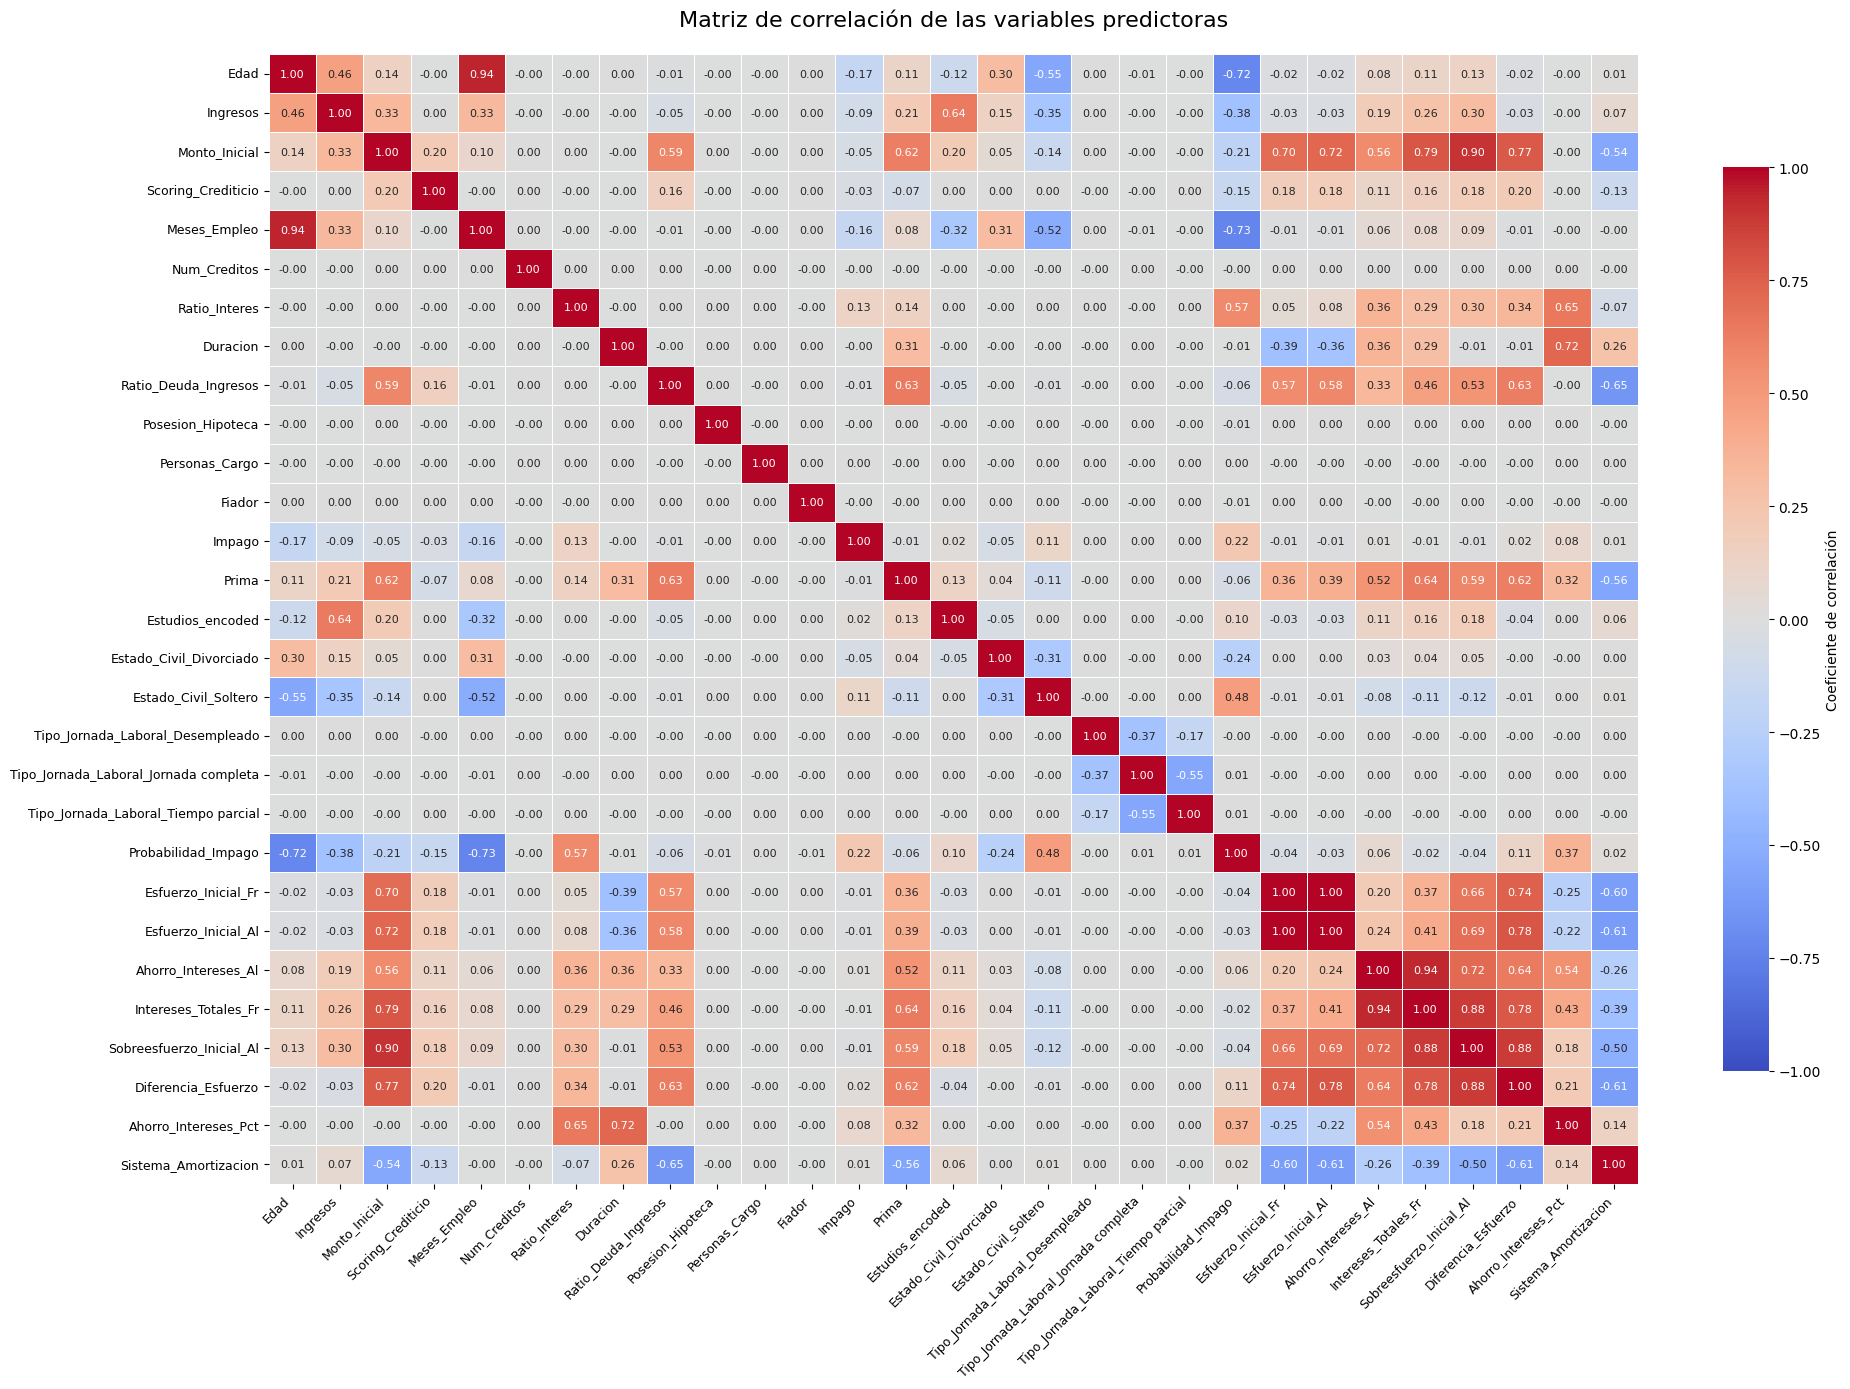

In [20]:
# Matriz de correlación de las variables que realmente entran al modelo
df_num = df.select_dtypes(include=['int64', 'float64'])
correlacion = df_num.corr()

plt.figure(figsize=(20, 14))

sns.heatmap(
    correlacion,
    annot=True,          # Mostrar los valores
    fmt=".2f",           # Dos decimales
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    annot_kws={"size": 8},
    cbar_kws={
        "label": "Coeficiente de correlación",
        "shrink": 0.8
    }
)

plt.title(
    "Matriz de correlación de las variables predictoras",
    fontsize=16,
    pad=20
)

plt.xticks(
    rotation=45,
    ha="right",
    fontsize=9
)

plt.yticks(
    rotation=0,
    fontsize=9
)

plt.tight_layout()
plt.show()

In [21]:
from sklearn.preprocessing import StandardScaler

# Columnas dummy (no se escalan) y el resto (sí se escalan)
dummy_cols = [c for c in X_train.columns if X_train[c].nunique() == 2]
num_cols = [c for c in X_train.columns if c not in dummy_cols]

# Creamos el escalador
scaler = StandardScaler()

# Escalamos las variables numéricas de entrenamiento
X_train_num_scal = pd.DataFrame(
    scaler.fit_transform(X_train[num_cols]),
    columns=num_cols,
    index=X_train.index
)

# Unimos las variables numéricas escaladas con las dummy originales
X_train_scaled = pd.concat(
    [X_train_num_scal, X_train[dummy_cols]], axis=1
)

# Escalamos las variables numéricas de test
X_test_num_scal = pd.DataFrame(
    scaler.transform(X_test[num_cols]),
    columns=num_cols,
    index=X_test.index
)

# Unimos las variables numéricas escaladas con las dummy originales
X_test_scaled = pd.concat(
    [X_test_num_scal, X_test[dummy_cols]], axis=1
)


In [22]:
X_train_scaled

,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,Estudios_encoded,...,Posesion_Hipoteca,Personas_Cargo,Fiador,Estado_Civil_Divorciado,Estado_Civil_Soltero,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Jornada completa,Tipo_Jornada_Laboral_Tiempo parcial,Sistema_Amortizacion,Ambos_Superan_Limite
18397,0.331519,1.019653,0.058735,-2.236118,0.173239,-1.001207,-0.144744,0.757498,-0.121440,0.078533,...,1,1,0,0,0,0,1,0,1,False
54204,0.331519,-0.447988,-0.112445,1.308996,0.617601,-0.002893,-0.344226,0.757498,-0.397403,-0.998559,...,1,0,0,0,0,0,0,0,0,True
145820,-1.751199,-1.542944,-0.859024,1.092414,-1.279227,-1.001207,-0.042379,-0.089539,-1.225292,-0.998559,...,0,0,1,0,1,0,1,0,1,False
148998,-1.255314,-0.633148,-0.677434,1.081015,-1.352182,0.995422,-1.073909,-0.936576,-1.225292,0.078533,...,0,0,1,0,1,1,0,0,1,False
38113,0.232342,1.841103,-0.351436,0.134891,-0.058890,-0.002893,0.731925,0.757498,0.706450,1.155625,...,1,1,1,1,0,0,0,1,1,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119879,0.629050,0.158481,-0.376969,-1.859949,0.869627,0.995422,-0.769437,-0.089539,-0.728558,-0.998559,...,1,1,0,0,0,0,1,0,1,False
103694,-0.065189,2.802077,-0.112445,-1.232999,-0.616001,-1.001207,-0.527959,0.757498,-1.004521,2.232717,...,0,0,0,0,0,0,0,0,1,False
131932,-1.354491,-0.653818,-0.752370,0.351473,-1.411872,-0.002893,-0.777311,1.604535,-0.176632,0.078533,...,0,1,0,0,1,0,1,0,1,False
146867,-1.255314,-0.926203,-0.112445,0.089294,-1.411872,-0.002893,1.871071,-0.089539,-0.287017,0.078533,...,0,0,0,0,1,0,1,0,0,True


## 2. Modelo lineal 


In [23]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, root_mean_squared_error, mean_absolute_error, r2_score

# Entrenamiento del modelo
modelo_lin = LinearRegression()
modelo_lin.fit(X_train_scaled, y_train)

# Predicciones
pred_train = modelo_lin.predict(X_train_scaled)
pred_test = modelo_lin.predict(X_test_scaled)

# Métricas
for nombre, y_real, y_pred in [("Train", y_train, pred_train), ("Test", y_test, pred_test)]:
    print(f"{nombre}:  MSE = {mean_squared_error(y_real, y_pred):.2f} | "
          f"RMSE = {root_mean_squared_error(y_real, y_pred):.2f} | "
          f"MAE = {mean_absolute_error(y_real, y_pred):.2f} | "
          f"R² = {r2_score(y_real, y_pred):.3f}")


Train:  MSE = 15831.43 | RMSE = 125.82 | MAE = 98.30 | R² = 0.779
Test:  MSE = 15854.08 | RMSE = 125.91 | MAE = 98.60 | R² = 0.777


## 3. Modelo polinómico

In [24]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_validate, KFold

def comparar_grados(X, y, grados=(1, 2, 3)):
    """Compara modelos de regresión polinómica de distintos grados mediante validación cruzada."""

    # Definimos cómo se divide el train en la validación cruzada:
    cv = KFold(n_splits=5, shuffle=True, random_state=42)

    # Lista donde iremos guardando los resultados de cada grado
    resultados = []

    # Repetimos el mismo proceso para cada grado del polinomio
    for g in grados:
        # Generamos las variables polinómicas
        # include_bias=False evita añadir una columna de unos, porque LinearRegression ya calcula el intercepto
        poly = PolynomialFeatures(degree=g, include_bias=False)
        X_poly = poly.fit_transform(X)

        # Validación cruzada de la regresión lineal sobre las variables polinómicas:
        # return_train_score=True guarda el error sobre los folds de entrenamiento
        # scoring calcula varias métricas a la vez (las de error vienen en negativo porque scikit-learn siempre maximiza)
        scores = cross_validate(LinearRegression(), X_poly, y, cv=cv, return_train_score=True,
                                scoring={"rmse": "neg_root_mean_squared_error",
                                         "mae": "neg_mean_absolute_error",
                                         "r2": "r2"})

        # Guardamos un resumen de este grado: la media de cada métrica en los 5 folds
        # El signo negativo delante de los errores los vuelve a poner en positivo
        resultados.append({
            "grado": g,
            "n_variables": X_poly.shape[1],               # número de columnas tras la transformación polinómica
            "RMSE_train": -scores["train_rmse"].mean(),   # error sobre los datos de train
            "RMSE_cv": -scores["test_rmse"].mean(),       # error sobre los folds no vistos(el que se usa de test)
            "MAE_cv": -scores["test_mae"].mean(),         # error absoluto medio en test (en gramos)
            "R2_cv": scores["test_r2"].mean()             # R cuadrado en test
        })

    # Convertimos la lista de resultados en una tabla con una fila por grado
    return pd.DataFrame(resultados)

# Aplicamos la función solo sobre el conjunto de entrenamiento (el test se reserva para la evaluación final)
resultados = comparar_grados(X_train_scaled, y_train)
resultados

,grado,n_variables,RMSE_train,RMSE_cv,MAE_cv,R2_cv
0,1,27,125.819536,125.853721,98.318949,0.779184
1,2,405,75.769019,76.114419,57.709743,0.919231
2,3,4059,61.648593,67.216418,46.021838,0.936492


El mejor modelo es el de grado 3, basándonos en el RMSE de validación, ya que obtiene el valor más bajo (64,587710 €). Además, su MAE es de 46,021838 € y su $R^2$  es de 0,936 lo que indica que explica aproximadamente el 93,6 % de la variabilidad de las primas. Por tanto, es el modelo que ofrece mejores resultados de predicción entre los tres modelos comparados.

Y podemos evaluar el conjunto de test con el mejor grado (el que logra menos error en el conjunto de train):

In [25]:
# idxmin() devuelve la fila donde RMSE_cv es mínimo, y .loc[fila, "grado"] extrae el grado de esa fila
# int() lo convierte en un entero normal, porque PolynomialFeatures necesita un número entero
mejor_grado = int(resultados.loc[resultados["RMSE_cv"].idxmin(), "grado"])

# Generamos las variables polinómicas con el grado elegido
poly = PolynomialFeatures(degree=mejor_grado, include_bias=False)
X_train_poly = poly.fit_transform(X_train_scaled)  
X_test_poly = poly.transform(X_test_scaled)        

# Entrenamos el modelo final con todo el conjunto de entrenamiento
modelo_final = LinearRegression()
modelo_final.fit(X_train_poly, y_train)

# Predecimos sobre el test: datos que el modelo no ha visto en ningún momento
pred_test = modelo_final.predict(X_test_poly)

# Evaluamos el modelo una única vez en test: esta es la estimación final de su rendimiento con datos nuevos
print(f"Mejor grado: {mejor_grado}")
print(f"Test:  RMSE = {root_mean_squared_error(y_test, pred_test):.2f} | "   
      f"MAE = {mean_absolute_error(y_test, pred_test):.2f} | "               
      f"R² = {r2_score(y_test, pred_test):.3f}")                             

Mejor grado: 3
Test:  RMSE = 78.63 | MAE = 45.93 | R² = 0.913


In [27]:
# Transformamos los datos de todos los clientes con el mismo escalador
X_num_scal = pd.DataFrame(
    scaler.transform(X[num_cols]),
    columns=num_cols,
    index=X.index
)

X_scaled = pd.concat([X_num_scal, X[dummy_cols]], axis=1)

# Creamos las variables polinómicas usando el grado elegido
X_poly = poly.transform(X_scaled)

# Calculamos la prima estimada de todos los clientes
primas_estimadas = modelo_final.predict(X_poly)

# Creamos un DataFrame con los resultados
df_primas = df.copy()
df_primas['Prima_Estimada'] = primas_estimadas

# Mostramos los resultados
df_primas["diferencia"] = df_primas["Prima"] - df_primas["Prima_Estimada"]

df_primas[['ID', 'Prima', 'Prima_Estimada', "diferencia"]]

,ID,Prima,Prima_Estimada,diferencia
0,KG9CT9,800.00,826.236255,-26.236255
1,V5O0K9,580.00,515.357098,64.642902
2,YE5GD0,130.00,106.304418,23.695582
3,Q6HQ3D,168.08,158.913499,9.166501
4,XO8CO4,293.94,331.684223,-37.744223
...,...,...,...,...
178601,VLZOS9,760.00,780.406303,-20.406303
178602,Z0BY9Y,542.47,631.542871,-89.072871
178603,ARBQ2V,188.19,150.710155,37.479845
178604,1LVUEW,58.46,91.699690,-33.239690


In [28]:
print(X_train_poly.shape)

(142884, 4059)


In [ ]:
from sklearn.model_selection import learning_curve
import numpy as np
import matplotlib.pyplot as plt

# Calculamos la curva de aprendizaje
train_sizes, train_scores, valid_scores = learning_curve(
    LinearRegression(),
    X_train_poly,
    y_train,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=5,
    scoring="neg_root_mean_squared_error"
)

# Calculamos el RMSE medio de entrenamiento y validación
train_rmse = -train_scores.mean(axis=1)
valid_rmse = -valid_scores.mean(axis=1)

# Representamos la curva de aprendizaje
plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_rmse, label="Entrenamiento")
plt.plot(train_sizes, valid_rmse, label="Validación")

plt.xlabel("Número de datos de entrenamiento")
plt.ylabel("RMSE")
plt.title("Curva de aprendizaje - Regresión polinómica")
plt.legend()
plt.grid()
plt.show()

# 4. Regularización

## 1. Lasso

In [ ]:
from sklearn.linear_model import Lasso, LassoCV
from sklearn.metrics import root_mean_squared_error
import numpy as np
from sklearn.preprocessing import PolynomialFeatures


poly = PolynomialFeatures(degree=mejor_grado, include_bias=False)
X_train_poly = poly.fit_transform(X_train_scaled)

# Buscamos el mejor alpha mediante validación cruzada
modeloLasso = LassoCV(
    alphas=np.logspace(-5, 2, 3),
    cv=3,
    max_iter=500).fit(X_train_poly, y_train)

# Mostramos el alpha elegido
print("Mejor alpha:", modeloLasso.alpha_)

# Creamos el modelo Lasso con el mejor alpha
lassoR = Lasso(alpha=modeloLasso.alpha_, max_iter=10000)

# Entrenamos el modelo
lassoR.fit(X_train_poly, y_train)

# Calculamos el error en train y test
print("Train RMSE: %0.4f" % root_mean_squared_error(y_train, lassoR.predict(X_train_poly)))
print("Test RMSE: %0.4f" % root_mean_squared_error(y_test, lassoR.predict(X_test_poly)))

# Mostramos los coeficientes
print(lassoR.coef_)

## 2.Ridge

### Busqueda de Hiperparametros

In [30]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import PolynomialFeatures

# Generamos las variables polinómicas con el grado elegido
poly = PolynomialFeatures(degree=mejor_grado, include_bias=False)
X_train_poly = poly.fit_transform(X_train_scaled)

# Creamos el modelo Ridge
reg_ridge = Ridge()

# Valores de alpha que vamos a probar
hyperparameter = {"alpha": [0.001, 0.01, 0.1, 1, 10, 100]}

# Buscamos el mejor alpha mediante validación cruzada
grid = GridSearchCV(
    estimator=reg_ridge,
    param_grid=hyperparameter,
    cv=5,
    scoring="neg_root_mean_squared_error"
)

grid.fit(X_train_poly, y_train)

# Mostramos los mejores resultados
print("Mejor modelo:", grid.best_estimator_)
print("Mejor alpha:", grid.best_params_)
print("Mejor RMSE de validación cruzada:", -grid.best_score_)

Mejor modelo: Ridge(alpha=0.01)
Mejor alpha: {'alpha': 0.01}
Mejor RMSE de validación cruzada: 64.21123680985369


In [31]:
# Transformamos las variables de test
X_test_poly = poly.transform(X_test_scaled)

# Predecimos con el mejor modelo Ridge
pred_ridge = grid.best_estimator_.predict(X_test_poly)

# Evaluamos el modelo
print(f"RMSE = {root_mean_squared_error(y_test, pred_ridge):.2f} | "
      f"MAE = {mean_absolute_error(y_test, pred_ridge):.2f} | "
      f"R² = {r2_score(y_test, pred_ridge):.3f}")

RMSE = 68.83 | MAE = 45.99 | R² = 0.934


## 3. Elastic net

In [ ]:
from sklearn.linear_model import ElasticNet
from sklearn.model_selection import GridSearchCV

# Generamos las variables polinómicas con el grado elegido
poly = PolynomialFeatures(degree=mejor_grado, include_bias=False)
X_train_poly = poly.fit_transform(X_train_scaled)

# Creamos el modelo Elastic Net
modelo = ElasticNet(max_iter=10000)

# Valores de alpha y l1_ratio que vamos a probar
hyperparameter = {
    "alpha": [0.001, 0.01, 0.1, 1, 10, 100],
    "l1_ratio": [0.1, 0.5, 0.7, 0.9, 1]
}

# Buscamos los mejores hiperparámetros mediante validación cruzada
grid = GridSearchCV(
    modelo, 
    hyperparameter,
    cv=5,
    scoring="neg_root_mean_squared_error"
)

grid.fit(X_train_poly, y_train)

# Mostramos los mejores resultados
print("Mejor modelo:", grid.best_estimator_)
print("Mejores hiperparámetros:", grid.best_params_)
print("Mejor RMSE de validación cruzada:", -grid.best_score_)

# Mostramos los coeficientes del mejor modelo
print("Coeficientes:", grid.best_estimator_.coef_)